### Import Libraries

In [2]:
import pandas as pd
import numpy as np
import unicodedata
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

### Read Dataset

In [3]:
customer = pd.read_csv("Dataset/olist_customers_dataset.csv")
order = pd.read_csv("Dataset/olist_orders_dataset.csv")
product = pd.read_csv("Dataset/olist_products_dataset.csv")
sellers = pd.read_csv("Dataset/olist_sellers_dataset.csv")
order_item = pd.read_csv("Dataset/olist_order_items_dataset.csv")
order_payment = pd.read_csv("Dataset/olist_order_payments_dataset.csv")
product_category = pd.read_csv("Dataset/product_category_name_translation.csv")
geolocation = pd.read_csv("Dataset/olist_geolocation_dataset.csv")
review = pd.read_csv("Dataset/olist_order_reviews_dataset.csv")

### Create Function for EDA

In [4]:
def checking_missing_value_and_duplicated(dataset):
    # Missing Values
    print(f"Missing Values: {dataset.isnull().any().sum()} Columns")

    # Duplicated Rows:
    print(f"Duplicated Rows:{len(dataset[dataset.duplicated()])} Rows")

In [5]:
# Plotting a bar chart for better data visualization
def bar_plot(x_axis,y_axis,x_label,y_label, title):
    bar_plot = px.bar(
        x = x_axis ,
        y = y_axis,
        text_auto = True,
        labels = {'x': x_label,'y': y_label},
        title = title)

    bar_plot.update_layout(width=600, height=400, title_x=0.5)
    return(bar_plot)

## **Customer Dataset Analysis**

In [6]:
customer.head(2)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP


In [7]:
print(f"The Customer dataset has {customer.shape[1]} columns and {customer.shape[0]} rows.")
print(f"Columns:\n{customer.columns}")

The Customer dataset has 5 columns and 99441 rows.
Columns:
Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')


In [8]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [9]:
print("Customer dataset:")
checking_missing_value_and_duplicated(customer)

Customer dataset:
Missing Values: 0 Columns
Duplicated Rows:0 Rows


In [10]:
unique_customer = customer['customer_unique_id'].nunique()
print(f"Number of unique customers: {unique_customer}")

Number of unique customers: 96096


#### What percentage of customers make only a single purchase, and what percentage return to the store?

In [11]:
customer_num = customer.groupby('customer_unique_id').size()

one_time_customer = (customer_num == 1).sum()   # Unique customers
repeat_customer = (customer_num > 1).sum()      # Customers who have made more than one purchase

# Creating a DataFrame of customer purchasing behavior
customer_behavior = pd.DataFrame({
    'customer' : ['one_time', 'repeat'],
    'count' : [one_time_customer, repeat_customer]
})
customer_behavior['percentage'] = ((customer_behavior['count'] / customer_behavior['count'].sum()) * 100).round(2)

# Drawing a pie chart for better understanding
fig = px.pie(customer_behavior, values='percentage', names='customer', title='Customer buying behavior')
fig.update_layout(width=400, height=400, title_x=0.5)


#### Distribution of customers across different states

In [12]:
customer_state_unique = customer['customer_state'].unique()
print(f"Number of unique customer states:{len(customer_state_unique)}\nStates:{customer_state_unique}")

customer_state = customer.groupby('customer_state')['customer_unique_id'].nunique().reset_index(name='unique_customers')
customer_state['customer_per_state'] = ((customer_state['unique_customers'] / customer_state['unique_customers'].sum())*100).round(2)
customer_state = customer_state.sort_values('customer_per_state', ascending=False)[:10]

bar_plot(customer_state['customer_state'],
         customer_state['customer_per_state'],
         'Names of the states','Percentage', "Each state's percentage of total customers(Top 10)")

Number of unique customer states:27
States:['SP' 'SC' 'MG' 'PR' 'RJ' 'RS' 'PA' 'GO' 'ES' 'BA' 'MA' 'MS' 'CE' 'DF'
 'RN' 'PE' 'MT' 'AM' 'AP' 'AL' 'RO' 'PB' 'TO' 'PI' 'AC' 'SE' 'RR']


#### Distribution of customers across different city

In [13]:
print(f"Number of unique customer city: {len(customer['customer_city'].unique())} ")
customer_city_number = customer.groupby('customer_city')['customer_unique_id'].nunique().reset_index(name='unique_customers')
customer_city_number = customer_city_number.sort_values('unique_customers', ascending=False)[:10]

bar_plot(customer_city_number['customer_city'],
         customer_city_number['unique_customers'],
         'Names of the city','count', 'The 10 city with the most customers')

Number of unique customer city: 4119 


## **Order Dataset Analysis**

In [14]:
order.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


In [15]:
print(f"The Order dataset has {order.shape[1]} columns and {order.shape[0]} rows.")
print(f"Columns:\n{order.columns}")

The Order dataset has 8 columns and 99441 rows.
Columns:
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')


In [16]:
order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [17]:
# Change the object time type to datetime
order_time_col = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in order_time_col:
    order[col] = pd.to_datetime(order[col], errors='coerce')

In [18]:
print("Order dataset:")
checking_missing_value_and_duplicated(order)

Order dataset:
Missing Values: 3 Columns


Duplicated Rows:0 Rows


#### Examining columns with null values

In [19]:
print("Which columns contain null values?")
order.isna().sum()[order.isna().sum() > 0]

Which columns contain null values?


order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

In [20]:
print(f"Order Approved NAN Value Status:")
order_approved_nan = order[order['order_approved_at'].isna()]
order_approved_nan.groupby('order_status').size().reset_index(name='count').sort_values('count', ascending=False)

Order Approved NAN Value Status:


,order_status,count
0,canceled,141
2,delivered,14
1,created,5


In [21]:
print("Order Delivered Customer NAN Value Status")
order_delivered_customer_nan = order[order['order_delivered_customer_date'].isna()]
order_delivered_customer_nan.groupby('order_status').size().reset_index(name='count').sort_values('count', ascending=False)

Order Delivered Customer NAN Value Status


,order_status,count
6,shipped,1107
1,canceled,619
7,unavailable,609
4,invoiced,314
5,processing,301
3,delivered,8
2,created,5
0,approved,2


In [22]:
print("Order Delivered Carrier NAN Value Status:")
order_delivered_carrier_nan = order[order['order_delivered_carrier_date'].isna()]
order_delivered_carrier_nan.groupby('order_status').size().reset_index(name='count').sort_values('count', ascending=False)

Order Delivered Carrier NAN Value Status:


,order_status,count
6,unavailable,609
1,canceled,550
4,invoiced,314
5,processing,301
2,created,5
0,approved,2
3,delivered,2


#### Analysis of Order Status Types

In [23]:
# Order Status
print(f"Order Status Types: {order['order_status'].unique()}")
order_status = order.groupby('order_status').size().reset_index(name='count')
order_status["Percentage"] = ((order_status['count'] / order_status['count'].sum()) * 100).round(3)
order_status.sort_values('Percentage', ascending=False)

Order Status Types: ['delivered' 'invoiced' 'shipped' 'processing' 'unavailable' 'canceled'
 'created' 'approved']


,order_status,count,Percentage
3,delivered,96478,97.020
6,shipped,1107,1.113
1,canceled,625,0.629
7,unavailable,609,0.612
4,invoiced,314,0.316
5,processing,301,0.303
2,created,5,0.005
0,approved,2,0.002


#### Distribution of the number of orders across the days of the week

In [23]:
order['order_purchase_day'] = order['order_purchase_timestamp'].dt.day_name()
order['order_purchase_month'] = order['order_purchase_timestamp'].dt.month_name()

In [24]:
order_days = order.groupby('order_purchase_day')['order_id'].nunique().reset_index(name='count').sort_values('count', ascending=False)

bar_plot(order_days['order_purchase_day'],
         order_days['count'],
         'Day of week', 'Count', 'Number of orders on weekdays')

#### Distribution of the number of orders per month

In [25]:
order_month = order.groupby('order_purchase_month')['order_id'].nunique().reset_index(name='count').sort_values('count', ascending=False)
order_month['percentage'] = ((order_month['count'] / order_month['count'].sum())*100).round(2)

bar_plot(order_month['order_purchase_month'],
         order_month['percentage'],
         'Month', 'Percentage', 'Percentage of orders per month')

#### Creating multiple time KPI

In [26]:
# create new dataset 
order_KPI = order.copy()

# Calculation of KPI
order_KPI["order_processing_time"] = order_KPI['order_delivered_carrier_date'] - order_KPI['order_purchase_timestamp']
order_KPI["shipping_to_delivery_time"] = order_KPI['order_delivered_customer_date'] - order_KPI['order_delivered_carrier_date']
order_KPI["total_delivery_time"] = order_KPI['order_delivered_customer_date'] - order_KPI['order_purchase_timestamp']
order_KPI["delivery_delay_duration"] = order_KPI['order_delivered_customer_date'] - order_KPI['order_estimated_delivery_date']

In [27]:
# Convert to seconds and then calculate the KPI on a daily basis
order_KPI["order_processing_time_days"] = order_KPI["order_processing_time"].dt.total_seconds() / 86400
order_KPI["shipping_to_delivery_time_days"] = order_KPI["shipping_to_delivery_time"].dt.total_seconds() / 86400
order_KPI["total_delivery_time_days"] = order_KPI["total_delivery_time"].dt.total_seconds() / 86400
order_KPI["delivery_delay_duration_days"] = order_KPI["delivery_delay_duration"] .dt.total_seconds() / 86400


# Save only the KPI columns in the new file
requird_time_col = ['order_id','order_processing_time', 'shipping_to_delivery_time',
                    'total_delivery_time', 'delivery_delay_duration',
                    'order_processing_time_days', 'shipping_to_delivery_time_days',
                    'total_delivery_time_days', 'delivery_delay_duration_days']
order_KPI = order_KPI[requird_time_col]

order_KPI.head(2)

,order_id,order_processing_time,shipping_to_delivery_time,total_delivery_time,delivery_delay_duration,order_processing_time_days,shipping_to_delivery_time_days,total_delivery_time_days,delivery_delay_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,2 days 08:58:27,6 days 01:30:13,8 days 10:28:40,-8 days +21:25:13,2.373924,6.06265,8.436574,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,1 days 17:49:23,12 days 00:56:45,13 days 18:46:08,-6 days +15:27:45,1.742627,12.03941,13.782037,-5.355729


In [28]:
order_KPI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype          
---  ------                          --------------  -----          
 0   order_id                        99441 non-null  object         
 1   order_processing_time           97658 non-null  timedelta64[ns]
 2   shipping_to_delivery_time       96475 non-null  timedelta64[ns]
 3   total_delivery_time             96476 non-null  timedelta64[ns]
 4   delivery_delay_duration         96476 non-null  timedelta64[ns]
 5   order_processing_time_days      97658 non-null  float64        
 6   shipping_to_delivery_time_days  96475 non-null  float64        
 7   total_delivery_time_days        96476 non-null  float64        
 8   delivery_delay_duration_days    96476 non-null  float64        
dtypes: float64(4), object(1), timedelta64[ns](4)
memory usage: 6.8+ MB


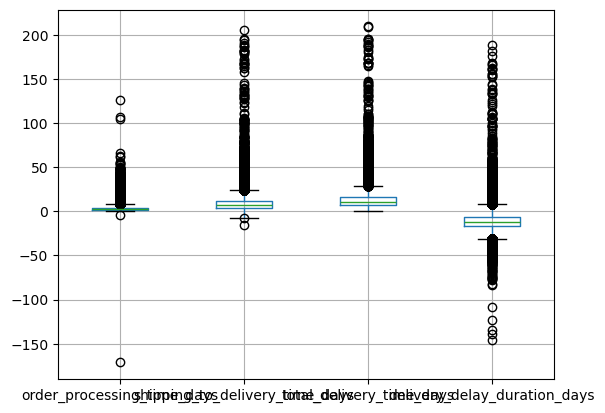

In [29]:
kpi_col = ['order_processing_time_days','shipping_to_delivery_time_days' ,'total_delivery_time_days', 'delivery_delay_duration_days']
pd.plotting.boxplot_frame(order_KPI[kpi_col])
plt.show()

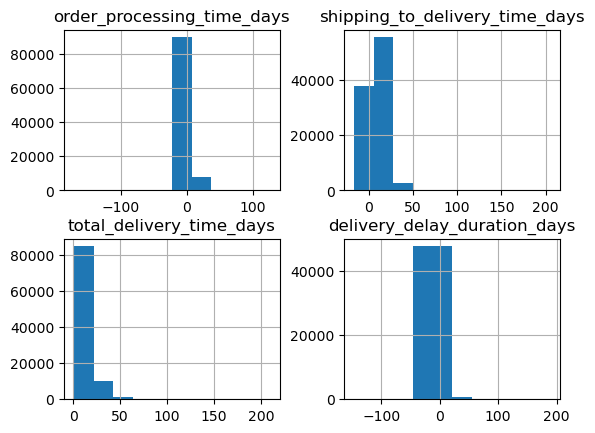

In [30]:
pd.plotting.hist_frame(order_KPI[kpi_col])
plt.show()

##### Function for analyzing KPI

In [31]:
# ----- Counting positive and negative , zero and null values ------ 
def counting_values(dataset, columns):
    nan_val = dataset[columns].isna().sum()
    neg_val =dataset[dataset[columns] < 0]
    zero_val =dataset[dataset[columns] == 0]
    pos_val = dataset[dataset[columns] > 0]
    return (nan_val, neg_val, zero_val, pos_val)

# ----- Print result of counting_values function  ------ 
def print_countig_values(nan_val, neg_val, zero_val, pos_val):  
    print(f"Number of negative values: {len(neg_val)}")
    print(f"Number of NAN values: {nan_val}")
    print(f"Number of zero values: {len(zero_val)}")
    print(f"Number of positive values: {len(pos_val)}")


# ----- Describe of positive values ------ 
def describe(pos_dataset, columns):
    describe_df = pd.DataFrame({
        'mean' : [pos_dataset[columns].mean()],
        'median' : [pos_dataset[columns].median()],
        'std' : [pos_dataset[columns].std()],
        'min' : [pos_dataset[columns].min()],
        'max' : [pos_dataset[columns].max()],
        'Q1' : [pos_dataset[columns].quantile(0.25)],
        'Q3' : [pos_dataset[columns].quantile(0.75)]
    })
    return describe_df


In [32]:
# --- order processing time days
print(f"order processing time days: Time between order purchase and order delivered carrier\n")
nan, neg, zero, pos = counting_values(order_KPI, 'order_processing_time_days')
print_countig_values(nan, neg, zero, pos)
print("\nDescribe of positive values: ")
describe(pos, 'order_processing_time_days')

order processing time days: Time between order purchase and order delivered carrier

Number of negative values: 166
Number of NAN values: 1783
Number of zero values: 0
Number of positive values: 97492

Describe of positive values: 


,mean,median,std,min,max,Q1,Q3
0,3.241404,2.208611,3.569041,0.00037,125.775521,1.132046,4.074387


In [33]:
# --- shipping to delivery time days
print(f"shipping to delivery time days: Time between order delivered carrier and order delivered customer \n")
nan, neg, zero, pos = counting_values(order_KPI, 'shipping_to_delivery_time_days')
print_countig_values(nan, neg, zero, pos)
print("\nDescribe of positive values: ")
describe(pos, 'shipping_to_delivery_time_days')

shipping to delivery time days: Time between order delivered carrier and order delivered customer 

Number of negative values: 23
Number of NAN values: 2966
Number of zero values: 9
Number of positive values: 96443

Describe of positive values: 


,mean,median,std,min,max,Q1,Q3
0,9.334422,7.100579,8.758769,0.000012,205.190972,4.102743,12.030874


In [34]:
# total delivery time days
print(f"total delivery time days: Time between order purchase and order delivered customer\n")
nan, neg, zero, pos = counting_values(order_KPI, 'total_delivery_time_days')
print_countig_values(nan, neg, zero, pos)
print("\nDescribe of positive values: ")
describe(pos, 'total_delivery_time_days')

total delivery time days: Time between order purchase and order delivered customer

Number of negative values: 0
Number of NAN values: 2965
Number of zero values: 0
Number of positive values: 96476

Describe of positive values: 


,mean,median,std,min,max,Q1,Q3
0,12.558702,10.217755,9.54653,0.533414,209.628611,6.766403,15.720327


#### Analysis of Delivery Delay
##### The difference between the actual delivery date and the estimated delivery date. A positive value indicates delivery occurred after the estimated date, while a negative value indicates it arrived earlier than estimated;if the value is Unknown, the order status must be checked.

In [35]:
def delivery_status(data):
    if pd.isna(data):
        return('Unknown')
    elif data > 0:
        return('Later')
    elif data < 0:
        return('Earlier')
    else:
        return('On_Time')

order_KPI['delivery_delay_status'] = order_KPI['delivery_delay_duration_days'].apply(delivery_status)

In [36]:
delivery_delay_status = order_KPI.groupby('delivery_delay_status').size().reset_index(name='count')

fig = px.pie(delivery_delay_status, values='count', names='delivery_delay_status', title='Analysis of Delivery Delay')
fig.update_layout(width=500, height=400, title_x=0.5)

In [37]:
# Save order KPI dataset as csv file
order_KPI_df = order_KPI.to_csv('order_kpi.csv', index=False)

## **Product Dataset Analysis**

In [38]:
product.head(2)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0


In [39]:
print(f"The Product dataset has {product.shape[1]} columns and {product.shape[0]} rows.")
print(f"Columns:\n{product.columns}")

The Product dataset has 9 columns and 32951 rows.
Columns:
Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')


In [40]:
product.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [41]:
print('Product dataset:')
checking_missing_value_and_duplicated(product)

Product dataset:
Missing Values: 8 Columns
Duplicated Rows:0 Rows


In [42]:
print("Which columns contain null values?")
product.isna().sum()[product.isna().sum() > 0]

Which columns contain null values?


product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

##### Product Category Analysis

In [43]:
# Merge with the category file to find the English names of the categories.
product_cat_en = pd.merge(product, product_category,
                    on= 'product_category_name',
                    how='left')

# Calculating the number of product categories
print(f"Number of product categories: {product['product_category_name'].nunique()}")
product_cat = product_cat_en.groupby('product_category_name_english').size().reset_index(name='count').sort_values('count', ascending=False)[:10]

# Displaying the 10 most frequent categories
bar_plot(product_cat['product_category_name_english'],
         product_cat['count'],
         'Product Categories','Count', 'Top 10 Product Categories')

Number of product categories: 73


##### Product photos Analysis

In [44]:
# Calculating the number of products with and without images and converting them into a DataFrame
not_photo = product['product_photos_qty'].isna().sum()
has_photo = product['product_photos_qty'].notna().sum()

product_photo = pd.DataFrame({
    'Photo_Status' : ['yes', 'no'],
    'count' : [has_photo, not_photo]
})

# Display using a chart to better compare products with and without photos
bar_plot(product_photo['Photo_Status'],
         product_photo['count'],
         'Status','Count', 'Products with Recorded Photo Quantity')

#### Analysis of product weight and dimension distribution

In [45]:
product['volume'] = (
    product['product_length_cm'] * 
    product['product_height_cm'] * 
    product['product_width_cm'] )


physical_col = ['product_weight_g','product_length_cm','product_height_cm','product_width_cm', 'volume']
product[physical_col].describe()

,product_weight_g,product_length_cm,product_height_cm,product_width_cm,volume
count,32949.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,2276.472488,30.815078,16.937661,23.196728,16564.096695
std,4282.038731,16.914458,13.637554,12.079047,27057.041650
min,0.000000,7.000000,2.000000,6.000000,168.000000
25%,300.000000,18.000000,8.000000,15.000000,2880.000000
50%,700.000000,25.000000,13.000000,20.000000,6840.000000
75%,1900.000000,38.000000,21.000000,30.000000,18480.000000
max,40425.000000,105.000000,105.000000,118.000000,296208.000000


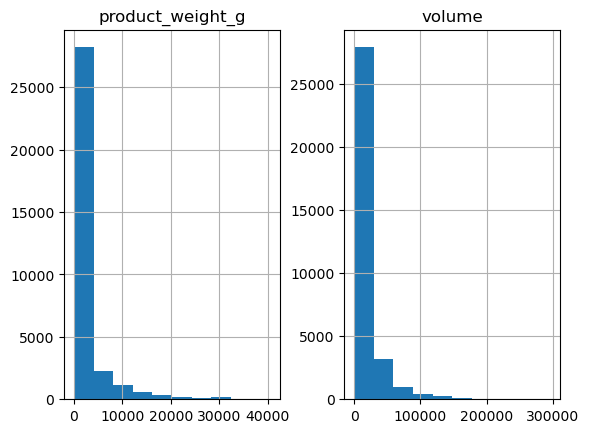

In [46]:
pd.plotting.hist_frame(product[['product_weight_g', 'volume']])
plt.show()

## **Seller Dataset Analysis**

In [47]:
sellers.head(2)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP


In [48]:
print(f"The Seller dataset has {sellers.shape[1]} columns and {sellers.shape[0]} rows.")
print(f"Columns:\n{sellers.columns}")

The Seller dataset has 4 columns and 3095 rows.
Columns:
Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'], dtype='object')


In [49]:
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [50]:
print('Sellerd dataset:')
checking_missing_value_and_duplicated(sellers)

Sellerd dataset:
Missing Values: 0 Columns
Duplicated Rows:0 Rows


In [51]:
print(f"Number of sellers: {len(sellers['seller_id'].unique())}")
print(f"Number of unique seller zip code prefix: {len(sellers['seller_zip_code_prefix'].unique())}")

Number of sellers: 3095
Number of unique seller zip code prefix: 2246


#### Distribution of Sellers by City

In [52]:
print(f"Number of unique cities of sellers: {len(sellers['seller_city'].unique())}")
sellers_city = sellers.groupby('seller_city').size().reset_index(name='count').sort_values('count', ascending=False)[:10]

bar_plot(sellers_city['seller_city'],
         sellers_city['count'],
         'Cities','Count', '10 cities with the highest number of sellers')

Number of unique cities of sellers: 611


#### Distribution of Sellers by State

In [53]:
print(f"Number of unique states of sellers: {len(sellers['seller_state'].unique())}")
sellers_state = sellers.groupby('seller_state').size().reset_index(name='count').sort_values('count', ascending=False)[:10]

bar_plot(sellers_state['seller_state'],
         sellers_state['count'],
         'States','Count', '10 States with the highest number of sellers')

Number of unique states of sellers: 23


##  **Order Item Dataset Analysis**

In [54]:
order_item.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


In [55]:
print(f"The Order Item dataset has {order_item.shape[1]} columns and {order_item.shape[0]} rows.")
print(f"Columns:\n{order_item.columns}")

The Order Item dataset has 7 columns and 112650 rows.
Columns:
Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')


In [56]:
order_item.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [57]:
print('Order Item dataset:')
checking_missing_value_and_duplicated(order_item)

Order Item dataset:
Missing Values: 0 Columns
Duplicated Rows:0 Rows


In [58]:
print(f"Number of unique Orders: {len(order_item['order_id'].unique())}")
print(f"Number of unique Products in orders: {len(order_item['product_id'].unique())}")
print(f"Number of unique Sellers: {len(order_item['seller_id'].unique())}")

Number of unique Orders: 98666
Number of unique Products in orders: 32951
Number of unique Sellers: 3095


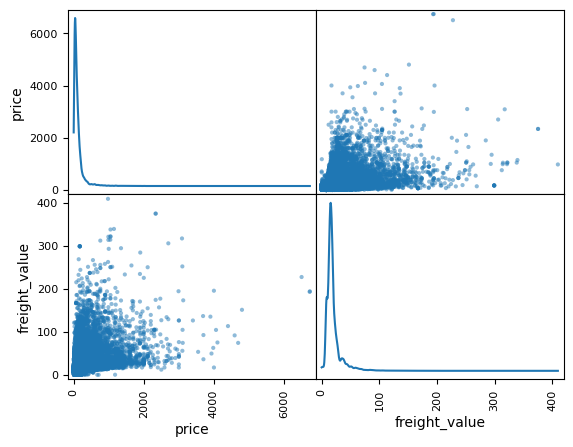

In [59]:
# scatter matrix
pd.plotting.scatter_matrix(order_item[['price','freight_value']], diagonal='kde')
plt.show()

In [60]:
order_item_group = order_item.groupby('order_id').agg(
    number_of_item = ('order_item_id', 'count'),
    total_freight = ('freight_value', 'sum'),
    total_price = ('price', 'sum')
).reset_index()

order_item_group.sort_values('number_of_item', ascending=False)

,order_id,number_of_item,total_freight,total_price
50137,8272b63d03f5f79c56e9e4120aec44ef,21,164.37,31.80
10459,1b15974a0141d54e36626dca3fdc731a,20,202.40,2000.00
65715,ab14fdcfbe524636d65ee38360e22ce8,20,288.80,1974.00
60941,9ef13efd6949e4573a18964dd1bbe7f5,15,18.00,765.00
25583,428a2f660dc84138d969ccd69a0ab6d5,15,243.30,982.35
...,...,...,...,...
98645,fff1e3e76b816bfe8ef16678cc53c643,1,20.86,65.99
98646,fff2cdc825f9fc0ba3c04227cfa02303,1,25.63,24.99
98647,fff2e9e3aa8644e19710216b4ef53ab2,1,16.25,69.90
98648,fff3983dfa3c5a0d752d8d17baa406a0,1,14.05,66.39


#### Comparison of the number of items and shipping costs

In [61]:
freight_by_items = order_item_group.groupby('number_of_item').agg(
    average_freight = ('total_freight', 'mean'),
    median_freight =('total_freight', 'median'),
    order_count =('order_id', 'count')
).reset_index()

bar_plot(freight_by_items['number_of_item'],
         freight_by_items['average_freight'],
         'Number of Items', 'Average Total Freight', 'Number of Items vs Average Order Freight')

#### Comparison of order value and shipping cost

In [62]:
scatter_plot = px.scatter(
    x=order_item_group['total_price'],
    y=order_item_group['total_freight'],
    labels={'x': 'Total Item Price (Excluding Freight)', 'y': 'Total Freight'},
    title='Order Value vs Total Freight'
)

scatter_plot.update_layout(width=600, height=400,title_x=0.5)

## **Order Payment Dataset Analysis**

In [63]:
order_payment.head(2)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39


In [64]:
print(f"The Order Payment dataset has {order_payment.shape[1]} columns and {order_payment.shape[0]} rows.")
print(f"Columns:\n{order_payment.columns}")

The Order Payment dataset has 5 columns and 103886 rows.
Columns:
Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')


In [65]:
order_payment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [66]:
print('Order Pyment dataset:')
checking_missing_value_and_duplicated(order_payment)

Order Pyment dataset:
Missing Values: 0 Columns
Duplicated Rows:0 Rows


#### Analysis of Payment Methods

In [67]:
unique_order = order_payment['order_id'].nunique()
print(f"Number of unique orders: {unique_order}")
print(f"Payment types: {order_payment['payment_type'].unique()}")

Number of unique orders: 99440
Payment types: ['credit_card' 'boleto' 'voucher' 'debit_card' 'not_defined']


In [68]:
order_payment_type = order_payment.groupby('payment_type').agg(
    order_count = ('order_id', 'nunique'),
    avg_payment = ('payment_value', 'mean')
).reset_index()

order_payment_type['percentage_per_type'] = ((order_payment_type['order_count'] / unique_order)*100).round(3)
order_count_payment_type = order_payment_type.sort_values('order_count', ascending=False)

bar_plot(order_count_payment_type['payment_type'], 
         order_count_payment_type['percentage_per_type'],
         'Payment Type', 'Percentage', 'Percentage of Orders Using Each Payment Method')

In [69]:
order_avg_payment_type = order_payment_type.sort_values('avg_payment', ascending=False)

bar_plot(order_avg_payment_type['payment_type'], 
         order_avg_payment_type['avg_payment'],
         'Payment Type', 'Average Payment', 'Average payment across different payment methods')

#### Orders with multiple payment methods

In [70]:
peyment_type = order_payment.groupby('order_id')['payment_type'].nunique()
multi_payment_type = peyment_type[peyment_type > 1]
multi_payment_type_df = order_payment[order_payment['order_id'].isin(multi_payment_type.index)]
print(f"The number of orders with multiple payment methods :{len(multi_payment_type)}")

payment_type_df = multi_payment_type_df.groupby('order_id').agg(
    payment_methods = ('payment_type', lambda x: ', '.join(sorted(x.unique())))
).reset_index()

payment_type_df = payment_type_df.groupby('payment_methods').size().reset_index(name='count')

bar_plot(payment_type_df['payment_methods'], 
         payment_type_df['count'],
         'Payment Types', 'Count', 'Hybrid payment methods')

The number of orders with multiple payment methods :2246


#### How many orders are included in each installment group?

In [71]:
payment_installment = order_payment.groupby('order_id').agg(
    max_installment = ('payment_installments', 'max'),
    total_payment = ("payment_value", 'sum')
).reset_index()

installment_analysis = payment_installment.groupby('max_installment').agg(
    order_count = ('order_id', 'nunique'),
    avg_payment = ('total_payment', 'mean')
).reset_index()

bar_plot(installment_analysis['max_installment'],
         installment_analysis['order_count'],
         'Number of installments', 'Number of orders', 'Number of orders per installment group')

#### What is the average order amount per group?

In [72]:
bar_plot(installment_analysis['max_installment'],
         installment_analysis['avg_payment'],
         'Number of installments', 'Average  Payment', 'Average payment per installment group')

## **Product Category Dataset Analysis**

In [73]:
product_category.head(2)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories


In [74]:
product_category.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


## **Geolocation Dataset Analysi**

In [75]:
geolocation.head(2)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP


In [76]:
geolocation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [77]:
print(f"Number of unique cities: {len(geolocation['geolocation_city'].unique())}")
print(f"Number of unique states: {len(geolocation['geolocation_state'].unique())}")

Number of unique cities: 8011
Number of unique states: 27


#### Distribution of cities

In [78]:
top_city_geo = geolocation.groupby('geolocation_city')['geolocation_zip_code_prefix'].nunique().reset_index(name='unique_zip_prefixes')
top_city_geo.sort_values('unique_zip_prefixes', ascending=False)[:10]

,geolocation_city,unique_zip_prefixes
6707,sao paulo,3171
7253,são paulo,3013
1035,brasilia,496
1046,brasília,406
5874,rio de janeiro,404
6046,salvador,275
2684,goiania,233
2700,goiânia,210
835,belo horizonte,205
2554,fortaleza,172


In [79]:
# Standardizing characters and eliminating phonetic variations
def normalize_city(city):
    if pd.isna(city):
        return city

    city = unicodedata.normalize('NFKD', city.strip()) 
    city = ''.join(
        char for char in city
        if not unicodedata.combining(char)
    )
    return city

geolocation['geolocation_city'] = geolocation['geolocation_city'].apply(normalize_city)

In [80]:
top_city_geo = geolocation.groupby('geolocation_city')['geolocation_zip_code_prefix'].nunique().reset_index(name='unique_zip_prefixes')
top_city_geo = top_city_geo.sort_values('unique_zip_prefixes', ascending=False)[:10]

bar_plot(top_city_geo['geolocation_city'], 
         top_city_geo['unique_zip_prefixes'],
         'cities', 'Count', '10 Most Frequent Cities')

#### Distribution of states

In [81]:
top_state_geo = geolocation.groupby('geolocation_state')['geolocation_zip_code_prefix'].nunique().reset_index(name='unique_zip_prefixes')
top_state_geo = top_state_geo.sort_values('unique_zip_prefixes', ascending=False)[:10]

bar_plot(top_state_geo['geolocation_state'], 
         top_state_geo['unique_zip_prefixes'],
         'States', 'Count', '10 Most Frequent States')

## **Review Dataset Analysis**

In [82]:
review.head(2)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13


In [83]:
review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


#### Orders with more than one review

In [84]:
count_order_review = review.groupby('order_id')['review_id'].size()
count_order_review = count_order_review[count_order_review > 1]
# count_order_review_df = review[review['order_id'].isin(count_order_review.index)]
print(f"Number of orders with more than one review: {len(count_order_review)}")

Number of orders with more than one review: 547


#### Distribution of Review Score

In [85]:
review_dist = review.groupby('review_score').size().reset_index(name='count')
review_dist['percentage'] = ((review_dist['count'] /review_dist['count'].sum())*100).round(2)

bar_plot(review_dist['review_score'], 
         review_dist['percentage'],
         'Review Score', 'Percentage', 'Distribution of Review Score')

#### Review Summery


In [86]:
review_summery = review.groupby('order_id').agg(
    number_review = ('review_id', 'count'),
    max_score = ('review_score', 'max'),
    min_score = ('review_score', 'min'),
    avg_score = ('review_score', 'mean')
).reset_index()

review_summery.sort_values('number_review', ascending=False)

,order_id,number_review,max_score,min_score,avg_score
1455,03c939fd7fd3b38f8485a0f95798f1f6,3,4,3,3.333333
54489,8e17072ec97ce29f0e1f111e598b0c85,3,1,1,1.000000
77319,c88b1d1b157a9999ce368f218a407141,3,5,3,4.333333
86232,df56136b8031ecd28e200bb18e6ddb2e,3,5,5,5.000000
48918,7f13a20e25350f4a55fb2a7c9a2e8d88,2,5,1,3.000000
...,...,...,...,...,...
98652,fff1e3e76b816bfe8ef16678cc53c643,1,4,4,4.000000
98653,fff2cdc825f9fc0ba3c04227cfa02303,1,2,2,2.000000
98654,fff2e9e3aa8644e19710216b4ef53ab2,1,5,5,5.000000
98655,fff3983dfa3c5a0d752d8d17baa406a0,1,5,5,5.000000


#### Comparison of comments with and without messages

In [87]:
not_msg = review['review_comment_message'].isna().sum()
has_msg = review['review_comment_message'].notna().sum()

review_msg = pd.DataFrame({
    'review_message' : ['yes', 'no'],
    'count' : [has_msg, not_msg]
})

bar_plot(review_msg['review_message'],
       review_msg['count'],
      'Review Message','count','Do the Review convey a message?')